# ПИС, ЛР1 — «Туристическая фирма» (тема 14)

Основная сущность — **Клиент**. Чтобы всё показать, выполните ячейки по порядку
(в Colab: *Среда выполнения → Выполнить все*).

## П.1. ER-модель (4 таблицы в 3НФ)

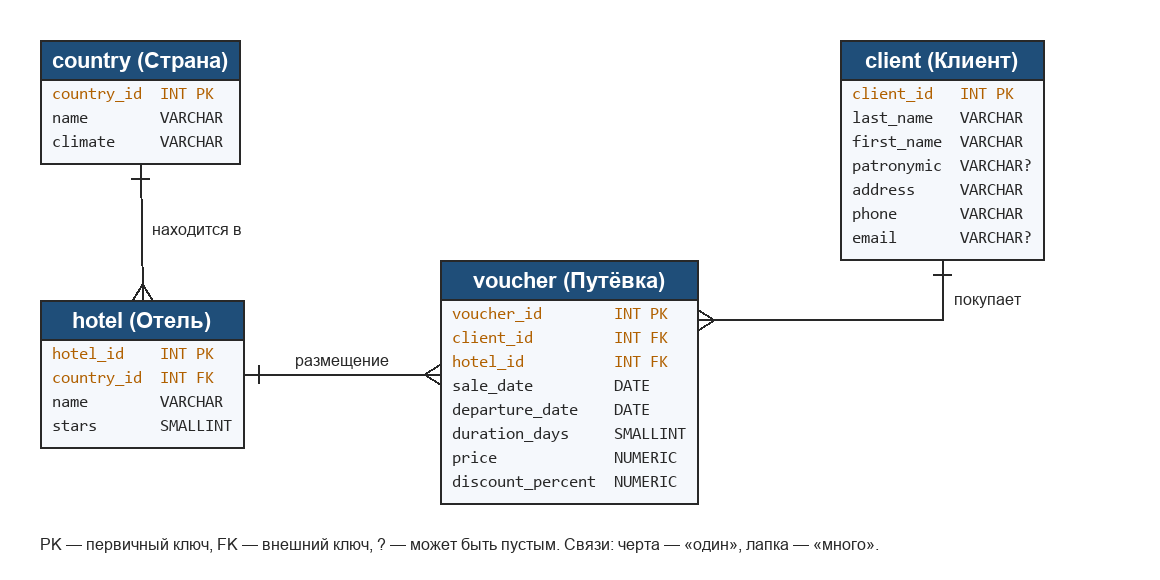

* **1НФ:** все атрибуты атомарны (ФИО разбито на 3 поля), повторяющихся групп нет.
* **2НФ:** ключи простые (суррогатные `*_id`), частичных зависимостей нет.
* **3НФ:** нет транзитивных зависимостей: климат хранится в `country`, класс отеля — в `hotel`,
  в `voucher` только ссылки на клиента и отель.

## П.2. Основная сущность — `client`

Независимые сущности (без внешних ключей): `country` (3 поля) и `client` (7 полей).
У клиента полей больше, поэтому ЛР1–ЛР4 делаются с ним.

## П.3–П.9. Классы

Базовый класс `ClientShort` — краткая версия клиента. В нём всё общее: инкапсуляция полей
(п.3), статические методы валидации (п.4) с общим `_validate_string` без повторов (п.5),
перегруженный конструктор (п.6), вывод и сравнение (п.7).

In [ ]:
"""Краткая версия клиента — базовый класс иерархии клиентов туристической фирмы."""
import json
import re


class ClientShort:
    """Краткие данные клиента: номер, ФИО (выводится с инициалами) и один контакт — телефон.

    Базовый класс иерархии: здесь всё общее для краткой и полной версии —
    перегруженный конструктор, разбор строк и JSON, валидация, общие поля,
    краткий вывод и сравнение. Наследник добавляет только свои поля.

    Все поля приватные, доступ только через свойства. Сеттеры проверяют значения,
    конструктор заполняет поля через сеттеры, поэтому объект с недопустимыми
    полями создать нельзя.
    """

    FIELDS = ("client_id", "last_name", "first_name", "patronymic", "phone")
    OPTIONAL_FIELDS = ("patronymic",)
    SEPARATOR = ";"

    NAME_PATTERN = r"[A-Za-zА-Яа-яЁё]+(-[A-Za-zА-Яа-яЁё]+)*"
    PHONE_PATTERN = r"(\+7|8)\d{10}"

    def __init__(self, *args, **kwargs):
        """Перегруженный конструктор. Варианты вызова (поля — в порядке FIELDS):

        ClientShort(1, "Иванов", "Иван", "Иванович", "+79161234567")
        ClientShort(client_id=1, last_name="Иванов", ...)          — именованные аргументы
        ClientShort({"client_id": 1, "last_name": "Иванов", ...})  — словарь
        ClientShort('{"client_id": 1, "last_name": "Иванов", ...}') — JSON-строка
        ClientShort("1;Иванов;Иван;Иванович;+79161234567")          — строка через «;»

        Необязательные поля (OPTIONAL_FIELDS) можно не передавать.
        Наследники получают все эти варианты вызова без изменений.
        """
        self._fill(self._collect_values(args, kwargs))

    @classmethod
    def _collect_values(cls, args, kwargs):
        """Приводит любой вариант вызова конструктора к словарю {поле: значение}."""
        if len(args) == 1 and not kwargs and isinstance(args[0], (str, dict)):
            data = args[0]
            values = cls._parse_string(data) if isinstance(data, str) else dict(data)
        else:
            if len(args) > len(cls.FIELDS):
                raise TypeError(f"слишком много аргументов: {len(args)}")
            values = dict(zip(cls.FIELDS, args))
            for key, value in kwargs.items():
                if key in values:
                    raise TypeError(f"{key}: значение передано дважды")
                values[key] = value

        unknown = set(values) - set(cls.FIELDS)
        if unknown:
            raise TypeError(f"неизвестные поля: {', '.join(sorted(unknown))}")
        missing = [f for f in cls.FIELDS if f not in values and f not in cls.OPTIONAL_FIELDS]
        if missing:
            raise TypeError(f"не заданы обязательные поля: {', '.join(missing)}")
        return values

    @classmethod
    def _parse_string(cls, text):
        """Разбирает JSON-объект или строку с полями через SEPARATOR в словарь."""
        text = text.strip()
        if text.startswith("{"):
            try:
                data = json.loads(text)
            except json.JSONDecodeError as e:
                raise ValueError(f"некорректный JSON: {e}") from None
            if not isinstance(data, dict):
                raise ValueError("JSON должен описывать объект")
            return data

        parts = [p.strip() for p in text.split(cls.SEPARATOR)]
        if len(parts) != len(cls.FIELDS):
            raise ValueError(f"в строке должно быть {len(cls.FIELDS)} полей через "
                             f"«{cls.SEPARATOR}», а не {len(parts)}")
        values = dict(zip(cls.FIELDS, parts))
        if values["client_id"].isdigit():
            values["client_id"] = int(values["client_id"])
        return values

    def _fill(self, values):
        """Заполняет поля через сеттеры (а значит, с проверкой).

        Наследник переопределяет метод и вызывает super()._fill(values).
        """
        self.client_id = values["client_id"]
        self.last_name = values["last_name"]
        self.first_name = values["first_name"]
        self.patronymic = values.get("patronymic")
        self.phone = values["phone"]

    # ---------- валидация (статические методы) ----------

    @staticmethod
    def _validate_string(value, field, max_len, *, required=True, min_len=1,
                         pattern=None, pattern_msg="неверный формат"):
        """Общая проверка строкового поля.

        Обрезает пробелы по краям. Необязательное поле (required=False)
        может быть None или пустой строкой — тогда возвращается None.
        """
        if value is None and not required:
            return None
        if not isinstance(value, str):
            raise TypeError(f"{field}: ожидается строка" + ("" if required else " или None"))
        value = value.strip()
        if not value:
            if not required:
                return None
            raise ValueError(f"{field}: не может быть пустым")
        if len(value) < min_len:
            raise ValueError(f"{field}: не короче {min_len} символов")
        if len(value) > max_len:
            raise ValueError(f"{field}: не длиннее {max_len} символов")
        if pattern and not re.fullmatch(pattern, value):
            raise ValueError(f"{field}: {pattern_msg}")
        return value

    @staticmethod
    def validate_client_id(value):
        if isinstance(value, bool) or not isinstance(value, int):
            raise TypeError("client_id: ожидается целое число")
        if value <= 0:
            raise ValueError("client_id: должен быть положительным")
        return value

    @staticmethod
    def validate_last_name(value):
        return ClientShort._validate_string(value, "last_name", 50,
                                            pattern=ClientShort.NAME_PATTERN,
                                            pattern_msg="только буквы и дефис")

    @staticmethod
    def validate_first_name(value):
        return ClientShort._validate_string(value, "first_name", 50,
                                            pattern=ClientShort.NAME_PATTERN,
                                            pattern_msg="только буквы и дефис")

    @staticmethod
    def validate_patronymic(value):
        return ClientShort._validate_string(value, "patronymic", 50, required=False,
                                            pattern=ClientShort.NAME_PATTERN,
                                            pattern_msg="только буквы и дефис")

    @staticmethod
    def validate_phone(value):
        if isinstance(value, str):
            value = re.sub(r"[\s()\-]", "", value)
        value = ClientShort._validate_string(value, "phone", 12,
                                             pattern=ClientShort.PHONE_PATTERN,
                                             pattern_msg="формат +7XXXXXXXXXX или 8XXXXXXXXXX")
        return "+7" + value[-10:]

    # ---------- свойства ----------

    @property
    def client_id(self):
        return self.__client_id

    @client_id.setter
    def client_id(self, value):
        self.__client_id = ClientShort.validate_client_id(value)

    @property
    def last_name(self):
        return self.__last_name

    @last_name.setter
    def last_name(self, value):
        self.__last_name = ClientShort.validate_last_name(value)

    @property
    def first_name(self):
        return self.__first_name

    @first_name.setter
    def first_name(self, value):
        self.__first_name = ClientShort.validate_first_name(value)

    @property
    def patronymic(self):
        return self.__patronymic

    @patronymic.setter
    def patronymic(self, value):
        self.__patronymic = ClientShort.validate_patronymic(value)

    @property
    def phone(self):
        return self.__phone

    @phone.setter
    def phone(self, value):
        self.__phone = ClientShort.validate_phone(value)

    # ---------- вывод и сравнение ----------

    def to_dict(self):
        """Все поля объекта в виде словаря (в порядке FIELDS своего класса)."""
        return {field: getattr(self, field) for field in self.FIELDS}

    def full_name(self):
        """Фамилия Имя Отчество (без отчества, если его нет)."""
        return " ".join(p for p in (self.last_name, self.first_name, self.patronymic) if p)

    def short_name(self):
        """Фамилия и инициалы: «Иванов И. И.»."""
        initials = " ".join(f"{p[0]}." for p in (self.first_name, self.patronymic) if p)
        return f"{self.last_name} {initials}"

    def short_str(self):
        """Краткая версия объекта: ФИО с инициалами и один контакт."""
        return f"{self.short_name()}, тел. {self.phone}"

    def __str__(self):
        """У краткой версии полный вывод совпадает с кратким."""
        return self.short_str()

    def __repr__(self):
        args = ", ".join(f"{k}={v!r}" for k, v in self.to_dict().items())
        return f"{type(self).__name__}({args})"

    def __eq__(self, other):
        """Равны объекты одного и того же класса с одинаковыми полями."""
        if type(other) is not type(self):
            return NotImplemented
        return self.to_dict() == other.to_dict()

Наследник `Client` — полная версия (п.8–9): добавляет только адрес, e-mail и полный вывод.

In [ ]:
"""Клиент туристической фирмы — полная версия."""


class Client(ClientShort):
    """Полные данные клиента туристической фирмы.

    Наследует от ClientShort конструктор (все варианты вызова), валидацию,
    общие поля (номер, ФИО, телефон), краткий вывод и сравнение.
    Добавляет только свои поля — адрес и e-mail — и полный вывод.
    """

    FIELDS = ("client_id", "last_name", "first_name", "patronymic", "address", "phone", "email")
    OPTIONAL_FIELDS = ClientShort.OPTIONAL_FIELDS + ("email",)

    EMAIL_PATTERN = r"[\w.+-]+@[\w-]+(\.[\w-]+)+"

    def _fill(self, values):
        super()._fill(values)
        self.address = values["address"]
        self.email = values.get("email")

    def to_short(self):
        """Краткая версия этого клиента (объект базового класса)."""
        return ClientShort(**{field: getattr(self, field) for field in ClientShort.FIELDS})

    # ---------- валидация собственных полей ----------

    @staticmethod
    def validate_address(value):
        return ClientShort._validate_string(value, "address", 200, min_len=5)

    @staticmethod
    def validate_email(value):
        return ClientShort._validate_string(value, "email", 100, required=False,
                                            pattern=Client.EMAIL_PATTERN,
                                            pattern_msg="некорректный адрес")

    # ---------- свойства собственных полей ----------

    @property
    def address(self):
        return self.__address

    @address.setter
    def address(self, value):
        self.__address = Client.validate_address(value)

    @property
    def email(self):
        return self.__email

    @email.setter
    def email(self, value):
        self.__email = Client.validate_email(value)

    # ---------- вывод ----------

    def __str__(self):
        """Полная версия объекта (переопределяет краткий вывод базового класса)."""
        return (f"Клиент №{self.client_id}: {self.full_name()}\n"
                f"  Адрес:   {self.address}\n"
                f"  Телефон: {self.phone}\n"
                f"  E-mail:  {self.email or '—'}")

## П.3. Инкапсуляция: поля приватные, доступ через свойства

In [ ]:
c = Client(1, "Иванов", "Иван", "Иванович", "г. Москва, ул. Ленина, д. 1",
           "+79161234567", "ivanov@mail.ru")
print(c.last_name, c.phone)           # через свойства — можно
try:
    print(c.__phone)                  # напрямую — нельзя
except AttributeError as e:
    print("AttributeError:", e)
print(vars(c))                        # имена полей «искажены» (name mangling)

## П.4–5. Валидация: объект с недопустимыми полями создать нельзя

In [ ]:
print(Client.validate_phone("8 (916) 123-45-67"))   # статический метод — без объекта

bad_cases = {
    "client_id": 0,
    "last_name": "Ив4нов",
    "address": "abc",
    "phone": "12345",
    "email": "not-an-email",
}
for field, value in bad_cases.items():
    data = c.to_dict()
    data[field] = value
    try:
        Client(data)
        print("создан?!", field)
    except (ValueError, TypeError) as e:
        print(f"{type(e).__name__}: {e}")

try:
    c.email = "bad@"                  # сеттер тоже проверяет
except ValueError as e:
    print("сеттер:", e)
print("e-mail не изменился:", c.email)

## П.6. Перегрузка конструктора

In [ ]:
by_fields = Client(1, "Иванов", "Иван", "Иванович", "г. Москва, ул. Ленина, д. 1",
                   "+79161234567", "ivanov@mail.ru")
by_kwargs = Client(client_id=2, last_name="Петрова", first_name="Анна",
                   address="г. Казань, ул. Баумана, 5", phone="89031112233")
by_dict = Client({"client_id": 3, "last_name": "Смирнов", "first_name": "Олег",
                  "address": "г. Сочи, ул. Морская, 3", "phone": "+79001234567"})
by_json = Client('{"client_id": 4, "last_name": "Кузнецова", "first_name": "Мария", '
                 '"patronymic": "Петровна", "address": "г. Тверь, пр. Мира, 10", '
                 '"phone": "8 912 000 11 22", "email": "mk@ya.ru"}')
by_string = Client("5;Орлов;Денис;;г. Пермь, ул. Ленина, 50;+79125556677;")

for client in (by_fields, by_kwargs, by_dict, by_json, by_string):
    print(repr(client))

## П.7. Полный и краткий вывод, сравнение

In [ ]:
print(by_json)                 # полная версия
print(by_json.short_str())     # краткая версия

same = Client("1;Иванов;Иван;Иванович;г. Москва, ул. Ленина, д. 1;8 916 123 45 67;"
              "ivanov@mail.ru")
print("by_fields == same:     ", by_fields == same)
print("by_fields == by_kwargs:", by_fields == by_kwargs)

## П.8–9. Краткий класс и иерархия наследования

In [ ]:
short = by_fields.to_short()
print(type(short).__name__, "->", short)
print(repr(short))
print("Client — наследник ClientShort:", issubclass(Client, ClientShort))
print("MRO:", [cls.__name__ for cls in Client.__mro__])

# краткий клиент создаётся теми же способами, что и полный — код не дублируется
print(ClientShort("7;Белов;Илья;Сергеевич;+79007654321"))

# методы, которые Client берёт у родителя, а не определяет заново
inherited = [m for m in ("__init__", "_parse_string", "validate_phone", "short_str", "__eq__")
             if m not in vars(Client)]
print("унаследованы:", inherited)

## П.10. Диаграмма классов

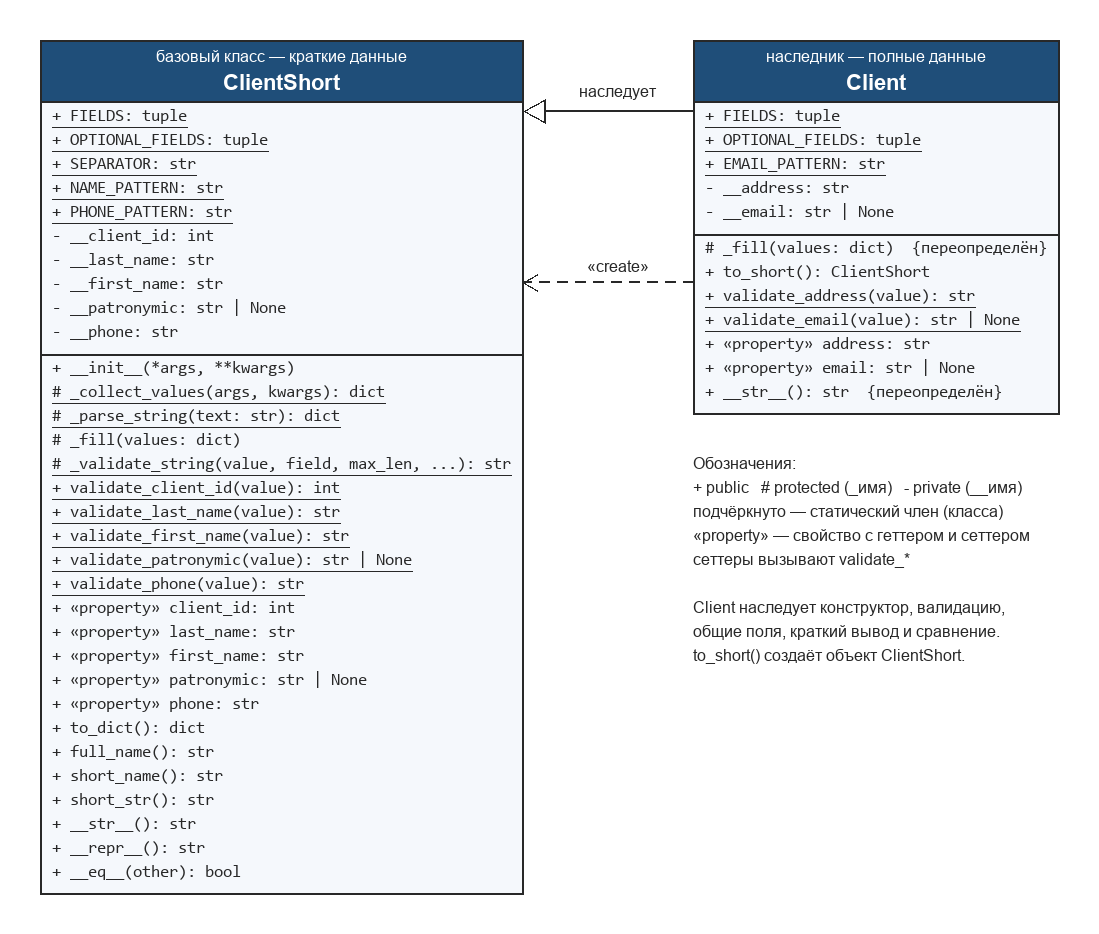